In [1]:
import json
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration esthétique des graphiques
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

DATA_DIR = Path("../data/nasa")

# 1. Chargement de Curiosity RAD (msl_rad_cruise_dose.csv)
df_rad = pd.read_csv(DATA_DIR / "msl_rad_cruise_dose.csv")
print("=== MSL RAD CRUISE DOSE ===")
print(f"Dimensions : {df_rad.shape}")
print("Colonnes :", df_rad.columns.tolist())
display(df_rad.head(3))

# 2. Aperçu de NOAA GOES (integral_protons)
with open(DATA_DIR / "goes/integral_protons_20261114.json", encoding="utf-8") as f:
    goes_raw = json.load(f)
df_goes = pd.DataFrame(goes_raw)
print("\n=== NOAA GOES PROTONS ===")
print(f"Dimensions : {df_goes.shape}")
print("Colonnes :", df_goes.columns.tolist())
display(df_goes.head(3))

=== MSL RAD CRUISE DOSE ===
Dimensions : (5117, 4)
Colonnes : ['utc', 'dose_rate_b_ugy_h', 'dose_rate_e_ugy_h', 'dose_equivalent_usv_h']


,utc,dose_rate_b_ugy_h,dose_rate_e_ugy_h,dose_equivalent_usv_h
0,2011-12-06T17:59:01+00:00,13.1896,15.1052,57.3996
1,2011-12-06T18:10:04+00:00,13.9306,16.0038,60.8143
2,2011-12-06T18:18:50+00:00,14.2347,14.9539,56.8248



=== NOAA GOES PROTONS ===
Dimensions : (16104, 4)
Colonnes : ['time_tag', 'satellite', 'flux', 'energy']


,time_tag,satellite,flux,energy
0,2026-11-07T14:15:00Z,18,1.728072,>=1 MeV
1,2026-11-07T14:15:00Z,18,0.233674,>=10 MeV
2,2026-11-07T14:15:00Z,18,0.222556,>=100 MeV


###titre

In [2]:
# Conversion de la colonne temporelle et tri chronologique
df_rad["utc"] = pd.to_datetime(df_rad["utc"])
df_rad = df_rad.sort_values("utc").reset_index(drop=True)

# Conversion du débit de dose équivalente (µSv/h) en dose journalière (mSv/jour)
# 1 jour = 24h et 1 mSv = 1000 µSv => facteur 24 / 1000 = 0.024
df_rad["dose_msv_day"] = df_rad["dose_equivalent_usv_h"] * 24 / 1000

print(f"Période couverte : du {df_rad['utc'].min()} au {df_rad['utc'].max()}")
print(f"Valeurs manquantes :\n{df_rad.isna().sum()}\n")

# Statistiques descriptives complètes
stats = df_rad[["dose_rate_b_ugy_h", "dose_rate_e_ugy_h", "dose_equivalent_usv_h", "dose_msv_day"]].describe()
display(stats.round(4))

mean_dose_msv_day = df_rad["dose_msv_day"].mean()
median_dose_msv_day = df_rad["dose_msv_day"].median()
max_dose_msv_day = df_rad["dose_msv_day"].max()

print(f"Dose équivalente moyenne : {mean_dose_msv_day:.3f} mSv/jour")
print(f"Dose équivalente médiane (bruit de fond GCR) : {median_dose_msv_day:.3f} mSv/jour")
print(f"Pic maximal enregistré : {max_dose_msv_day:.3f} mSv/jour")

Période couverte : du 2011-12-06 17:59:01+00:00 au 2012-07-13 23:51:59+00:00
Valeurs manquantes :
utc                      0
dose_rate_b_ugy_h        0
dose_rate_e_ugy_h        0
dose_equivalent_usv_h    0
dose_msv_day             0
dtype: int64



,dose_rate_b_ugy_h,dose_rate_e_ugy_h,dose_equivalent_usv_h,dose_msv_day
count,5117.0000,5117.0000,5117.0000,5117.0000
mean,22.2929,22.9410,87.1760,2.0922
std,57.2239,38.3932,145.8942,3.5015
min,1.5696,1.7225,6.5455,0.1571
25%,13.4446,17.7282,67.3672,1.6168
50%,14.3461,18.2945,69.5192,1.6685
75%,15.8503,19.0863,72.5280,1.7407
max,1039.1109,671.5494,2551.8879,61.2453


Dose équivalente moyenne : 2.092 mSv/jour
Dose équivalente médiane (bruit de fond GCR) : 1.668 mSv/jour
Pic maximal enregistré : 61.245 mSv/jour


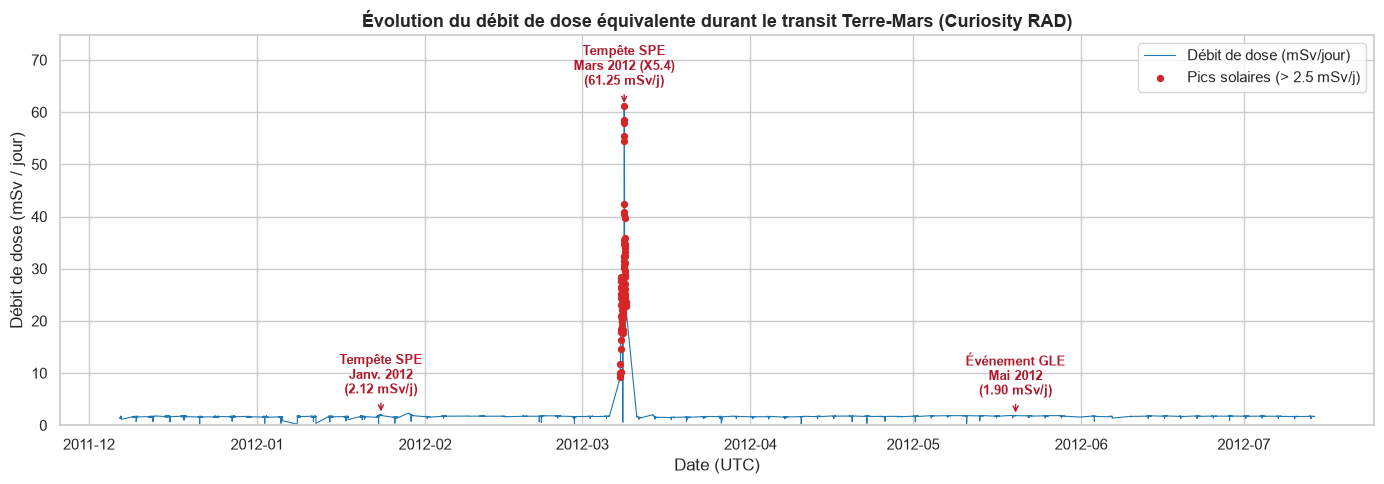

In [3]:
# Seuil empirique pour isoler les tempêtes solaires (SPE) au-dessus du fond galactique (GCR ~ 1.4 - 1.8 mSv/j)
seuil_pic = 2.5
pics_solaires = df_rad[df_rad["dose_msv_day"] > seuil_pic]

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df_rad["utc"], df_rad["dose_msv_day"], color="#1f77b4", linewidth=0.8, label="Débit de dose (mSv/jour)")
ax.scatter(pics_solaires["utc"], pics_solaires["dose_msv_day"], color="#d62728", s=18, zorder=5, label=f"Pics solaires (> {seuil_pic} mSv/j)")

# Annotation des événements solaires majeurs du transit MSL (Janvier, Mars, Mai 2012)
evenements = [
    ("2012-01-23", "Tempête SPE\nJanv. 2012"),
    ("2012-03-07", "Tempête SPE\nMars 2012 (X5.4)"),
    ("2012-05-17", "Événement GLE\nMai 2012"),
]
for date_str, label in evenements:
    t = pd.to_datetime(date_str, utc=True)
    # Trouver la valeur maximale autour de chaque événement (+/- 4 jours)
    fenetre = df_rad[(df_rad["utc"] >= t - pd.Timedelta(days=2)) & (df_rad["utc"] <= t + pd.Timedelta(days=5))]
    if not fenetre.empty:
        idx_max = fenetre["dose_msv_day"].idxmax()
        row_max = df_rad.loc[idx_max]
        ax.annotate(
            f"{label}\n({row_max['dose_msv_day']:.2f} mSv/j)",
            xy=(row_max["utc"], row_max["dose_msv_day"]),
            xytext=(0, 15),
            textcoords="offset points",
            ha="center",
            fontsize=9,
            fontweight="bold",
            color="#b2182b",
            arrowprops=dict(arrowstyle="->", color="#b2182b", lw=1),
        )

ax.set_title("Évolution du débit de dose équivalente durant le transit Terre-Mars (Curiosity RAD)", fontsize=13, fontweight="bold")
ax.set_xlabel("Date (UTC)")
ax.set_ylabel("Débit de dose (mSv / jour)")
ax.set_ylim(0, df_rad["dose_msv_day"].max() * 1.22)
ax.legend()
plt.tight_layout()
plt.show()

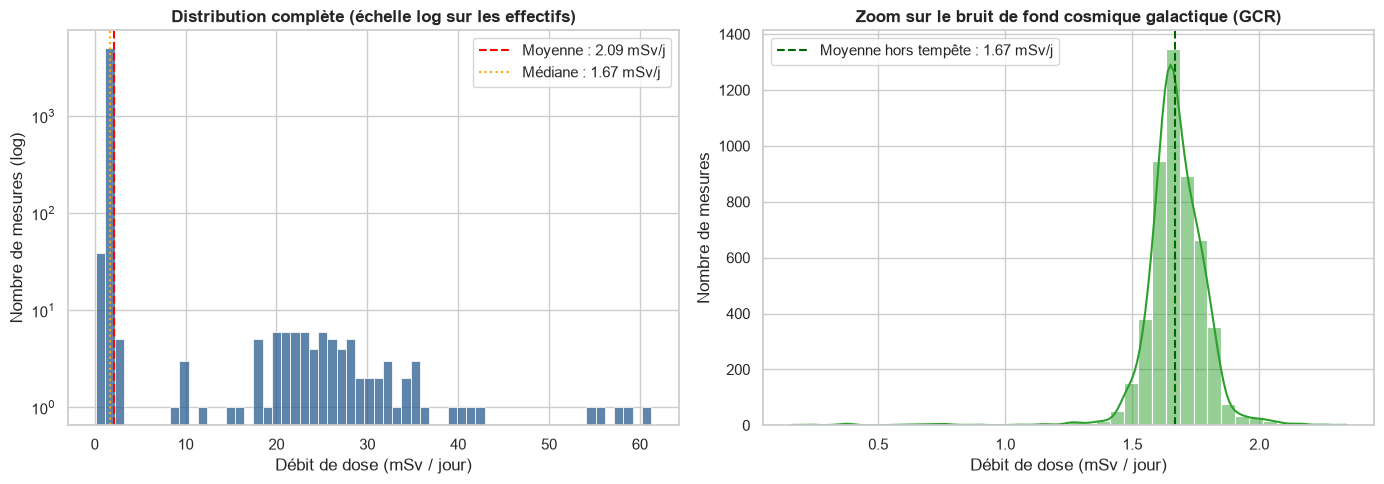

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Vue 1 : Échelle complète avec axe Y logarithmique (pour voir la longue traîne des pics solaires)
sns.histplot(df_rad["dose_msv_day"], bins=60, color="#2b5c8f", ax=axes[0])
axes[0].set_yscale("log")
axes[0].axvline(mean_dose_msv_day, color="red", linestyle="--", label=f"Moyenne : {mean_dose_msv_day:.2f} mSv/j")
axes[0].axvline(median_dose_msv_day, color="orange", linestyle=":", label=f"Médiane : {median_dose_msv_day:.2f} mSv/j")
axes[0].set_title("Distribution complète (échelle log sur les effectifs)", fontweight="bold")
axes[0].set_xlabel("Débit de dose (mSv / jour)")
axes[0].set_ylabel("Nombre de mesures (log)")
axes[0].legend()

# Vue 2 : Zoom sur le bruit de fond galactique (GCR < 2.5 mSv/j)
gcr_only = df_rad[df_rad["dose_msv_day"] <= 2.5]["dose_msv_day"]
sns.histplot(gcr_only, bins=40, kde=True, color="#2ca02c", ax=axes[1])
axes[1].axvline(gcr_only.mean(), color="darkgreen", linestyle="--", label=f"Moyenne hors tempête : {gcr_only.mean():.2f} mSv/j")
axes[1].set_title("Zoom sur le bruit de fond cosmique galactique (GCR)", fontweight="bold")
axes[1].set_xlabel("Débit de dose (mSv / jour)")
axes[1].set_ylabel("Nombre de mesures")
axes[1].legend()

plt.tight_layout()
plt.show()

Durée réelle observée : 220.2 jours (dose intégrée = 421.76 mSv)
Dose cumulée extrapolée à 210 jours (via moyenne)     : 439.37 mSv (73.2% de la limite NASA)
Dose cumulée extrapolée à 210 jours (via intégration) : 402.14 mSv (67.0% de la limite NASA)
Aller-retour Mars (420 jours, sans surface)           : 804.29 mSv (134.0% de la limite NASA)


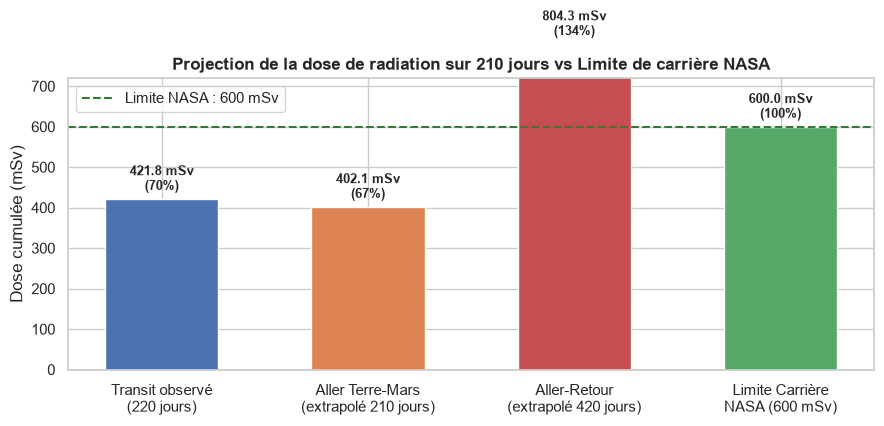

In [5]:
DUREE_TRANSIT_JOURS = 210
LIMITE_NASA_MSV = 600.0

# 1. Extrapolation basée sur le débit moyen global (incluant les tempêtes solaires)
dose_210j_moyenne = mean_dose_msv_day * DUREE_TRANSIT_JOURS

# 2. Intégration trapézoïdale exacte sur la durée réelle du jeu de données, puis mise à l'échelle à 210j
duree_reelle_heures = (df_rad["utc"].max() - df_rad["utc"].min()).total_seconds() / 3600
# Conversion en heures depuis le début pour intégration numérique
heures_ecoulees = (df_rad["utc"] - df_rad["utc"].min()).dt.total_seconds() / 3600
dose_totale_observee_msv = np.trapezoid(df_rad["dose_equivalent_usv_h"], heures_ecoulees) / 1000
dose_210j_integree = dose_totale_observee_msv * (DUREE_TRANSIT_JOURS * 24 / duree_reelle_heures)

pct_limite_moy = (dose_210j_moyenne / LIMITE_NASA_MSV) * 100
pct_limite_int = (dose_210j_integree / LIMITE_NASA_MSV) * 100

print(f"Durée réelle observée : {duree_reelle_heures / 24:.1f} jours (dose intégrée = {dose_totale_observee_msv:.2f} mSv)")
print(f"Dose cumulée extrapolée à 210 jours (via moyenne)     : {dose_210j_moyenne:.2f} mSv ({pct_limite_moy:.1f}% de la limite NASA)")
print(f"Dose cumulée extrapolée à 210 jours (via intégration) : {dose_210j_integree:.2f} mSv ({pct_limite_int:.1f}% de la limite NASA)")
print(f"Aller-retour Mars (420 jours, sans surface)           : {dose_210j_integree * 2:.2f} mSv ({pct_limite_int * 2:.1f}% de la limite NASA)")

# Graphique comparatif
fig, ax = plt.subplots(figsize=(9, 4.5))
categories = [
    f"Transit observé\n({duree_reelle_heures/24:.0f} jours)",
    "Aller Terre-Mars\n(extrapolé 210 jours)",
    "Aller-Retour\n(extrapolé 420 jours)",
    "Limite Carrière\nNASA (600 mSv)"
]
valeurs = [dose_totale_observee_msv, dose_210j_integree, dose_210j_integree * 2, LIMITE_NASA_MSV]
couleurs = ["#4c72b0", "#dd8452", "#c44e52", "#55a868"]

bars = ax.bar(categories, valeurs, color=couleurs, width=0.55)
ax.axhline(LIMITE_NASA_MSV, color="#2e7d32", linestyle="--", linewidth=1.5, label="Limite NASA : 600 mSv")

for bar, val in zip(bars, valeurs):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 12, f"{val:.1f} mSv\n({val/LIMITE_NASA_MSV*100:.0f}%)",
            ha="center", va="bottom", fontsize=9.5, fontweight="bold")

ax.set_ylim(0, LIMITE_NASA_MSV * 1.2)
ax.set_ylabel("Dose cumulée (mSv)")
ax.set_title("Projection de la dose de radiation sur 210 jours vs Limite de carrière NASA", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.show()

Corrélation de Pearson  (B vs E) : r = 0.9885
Corrélation de Spearman (B vs E) : rho = 0.3101


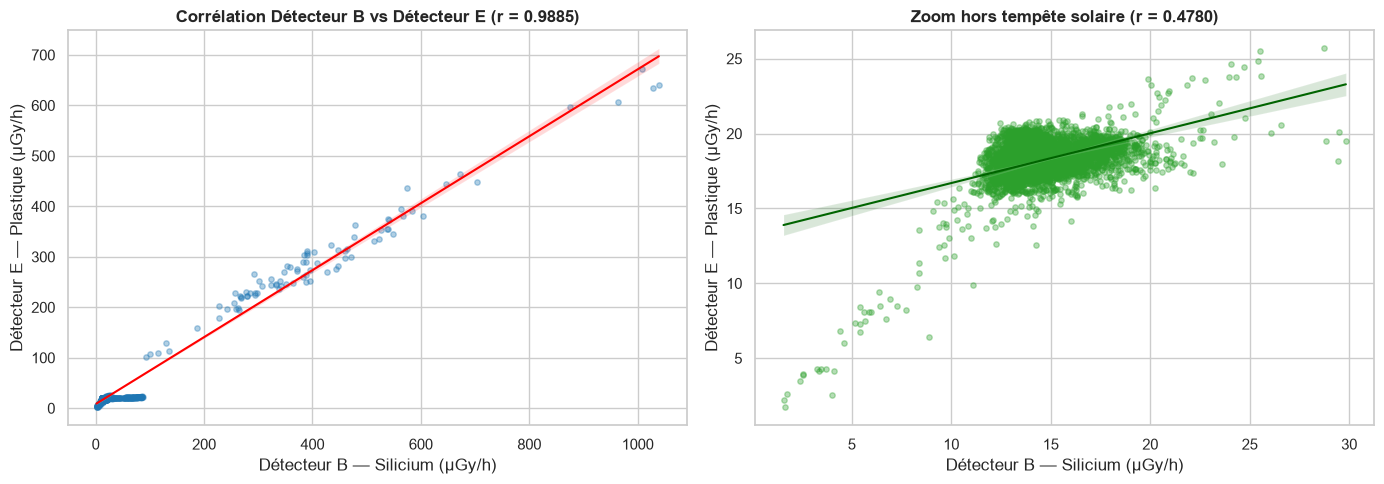

In [6]:
corr_pearson = df_rad["dose_rate_b_ugy_h"].corr(df_rad["dose_rate_e_ugy_h"], method="pearson")
corr_spearman = df_rad["dose_rate_b_ugy_h"].corr(df_rad["dose_rate_e_ugy_h"], method="spearman")

print(f"Corrélation de Pearson  (B vs E) : r = {corr_pearson:.4f}")
print(f"Corrélation de Spearman (B vs E) : rho = {corr_spearman:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Nuage de points global
sns.regplot(
    data=df_rad,
    x="dose_rate_b_ugy_h",
    y="dose_rate_e_ugy_h",
    scatter_kws={"alpha": 0.35, "s": 15, "color": "#1f77b4"},
    line_kws={"color": "red", "lw": 1.5},
    ax=axes[0],
)
axes[0].set_title(f"Corrélation Détecteur B vs Détecteur E (r = {corr_pearson:.4f})", fontweight="bold")
axes[0].set_xlabel("Détecteur B — Silicium (µGy/h)")
axes[0].set_ylabel("Détecteur E — Plastique (µGy/h)")

# Zoom sur le régime calme (GCR < 30 µGy/h)
calme = df_rad[df_rad["dose_rate_b_ugy_h"] < 30]
r_calme = calme["dose_rate_b_ugy_h"].corr(calme["dose_rate_e_ugy_h"])
sns.regplot(
    data=calme,
    x="dose_rate_b_ugy_h",
    y="dose_rate_e_ugy_h",
    scatter_kws={"alpha": 0.35, "s": 15, "color": "#2ca02c"},
    line_kws={"color": "darkgreen", "lw": 1.5},
    ax=axes[1],
)
axes[1].set_title(f"Zoom hors tempête solaire (r = {r_calme:.4f})", fontweight="bold")
axes[1].set_xlabel("Détecteur B — Silicium (µGy/h)")
axes[1].set_ylabel("Détecteur E — Plastique (µGy/h)")

plt.tight_layout()
plt.show()

=== ANALYSE NOAA GOES (>=10 MeV) ===
Période GOES : du 2026-11-07 14:15:00+00:00 au 2026-11-14 14:05:00+00:00
Nombre total de mesures (>=10 MeV) : 2013
Nombre de dépassements du seuil de 10.0 pfu : 0
Flux maximal observé : 0.4807 pfu
Aucun dépassement >= 10 pfu sur cette fenêtre temporelle (conditions solaires calmes).


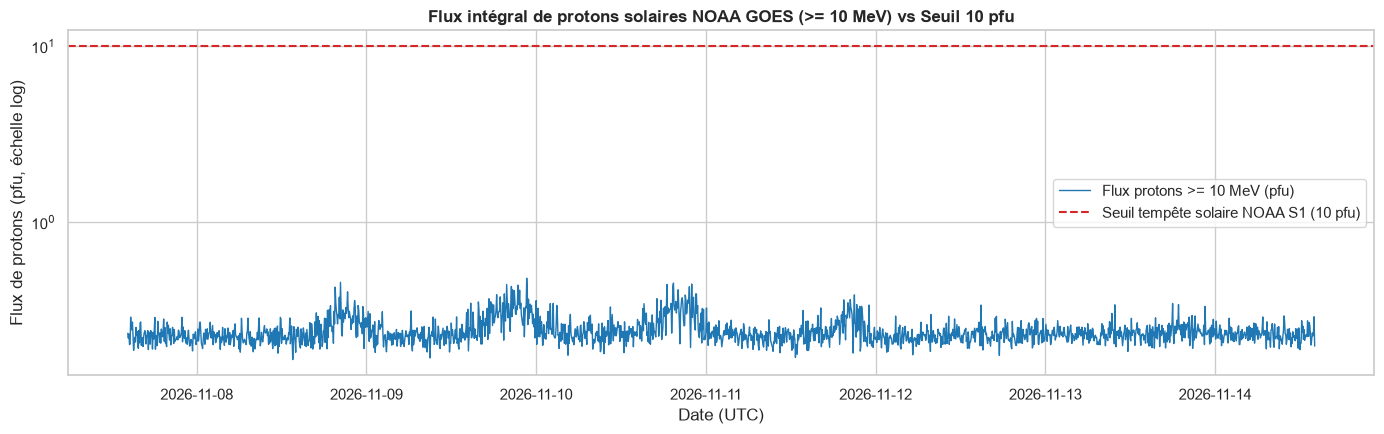


=== SYNTHÈSE DES ÉVÉNEMENTS HISTORIQUES NASA DONKI ===
- cme_20170901_20170930.json : 29 événements enregistrés
- cme_20240501_20240531.json : 144 événements enregistrés
- sep_20170901_20170930.json : 10 événements enregistrés
- sep_20240501_20240531.json : 14 événements enregistrés


In [7]:
df_goes["time_tag"] = pd.to_datetime(df_goes["time_tag"])

# Filtrer le canal >= 10 MeV (référence NOAA pour les tempêtes de radiations solaires S1)
goes_10mev = df_goes[df_goes["energy"] == ">=10 MeV"].sort_values("time_tag").copy()
SEUIL_PFU = 10.0
depassements = goes_10mev[goes_10mev["flux"] >= SEUIL_PFU]

print("=== ANALYSE NOAA GOES (>=10 MeV) ===")
print(f"Période GOES : du {goes_10mev['time_tag'].min()} au {goes_10mev['time_tag'].max()}")
print(f"Nombre total de mesures (>=10 MeV) : {len(goes_10mev)}")
print(f"Nombre de dépassements du seuil de {SEUIL_PFU} pfu : {len(depassements)}")
print(f"Flux maximal observé : {goes_10mev['flux'].max():.4f} pfu")

if not depassements.empty:
    display(depassements[["time_tag", "satellite", "flux", "energy"]].head(10))
else:
    print("Aucun dépassement >= 10 pfu sur cette fenêtre temporelle (conditions solaires calmes).")

# Graphique du flux de protons GOES (>=10 MeV) vs seuil d'alerte 10 pfu
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(goes_10mev["time_tag"], goes_10mev["flux"], color="#1f77b4", lw=1, label="Flux protons >= 10 MeV (pfu)")
ax.axhline(SEUIL_PFU, color="#d62728", linestyle="--", lw=1.5, label="Seuil tempête solaire NOAA S1 (10 pfu)")
if not depassements.empty:
    ax.scatter(depassements["time_tag"], depassements["flux"], color="red", s=20, zorder=5, label="Dépassements >= 10 pfu")

ax.set_yscale("log")
ax.set_title("Flux intégral de protons solaires NOAA GOES (>= 10 MeV) vs Seuil 10 pfu", fontweight="bold")
ax.set_xlabel("Date (UTC)")
ax.set_ylabel("Flux de protons (pfu, échelle log)")
ax.legend()
plt.tight_layout()
plt.show()

# Synthèse des événements historiques DONKI (2017 et 2024)
print("\n=== SYNTHÈSE DES ÉVÉNEMENTS HISTORIQUES NASA DONKI ===")
for json_file in sorted((DATA_DIR / "donki").glob("*.json")):
    with open(json_file, encoding="utf-8") as f:
        events = json.load(f)
    print(f"- {json_file.name} : {len(events)} événements enregistrés")